# Track T4: Multi-Layer Perceptron (MLP) Modeling, Tuning & Explainability
**Student Owner:** B2 (Evaluation Architect & Neural Network Specialist)

This notebook covers:
1. **Stage 9 Supervised Modeling:** Baseline `mlp_regressor` and `mlp_classifier`.
2. **Architectural Comparison:** Method 1 (Dedicated Softmax Classifier) vs. Method 2 (Thresholded Regressor).
3. **Stage 10 Hyperparameter Tuning:** `TimeSeriesSplit` cross-validation with `GridSearchCV` / `RandomizedSearchCV`.
4. **Evaluation:** Testing across 2023 all-season chronological test set and 7 Unseen Stations.
5. **Default vs. Tuned Comparison Table.**
6. **Stage 11 / Task 7 Explainability & Error Analysis:** Permutation Importance, Partial Dependence Plots (PDP), and Top 3 Failure Cases.

In [1]:
import sys
import time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.features import build_b2_features
from src.models.mlp import (
    build_mlp_regressor,
    build_mlp_classifier,
    prepare_mlp_data,
    get_clean_features,
    run_mlp_experiment,
    tune_mlp_regressor,
    threshold_health_score,
    plot_permutation_importance,
    plot_partial_dependence,
    get_top_failure_cases,
)
from src.evaluate import split_chronological, split_unseen_stations, evaluate_regression, evaluate_classification
print("Setup completed successfully.")

Setup completed successfully.


## 1. Load Real Dataset and Perform Chronological Splits

In [2]:
parquet_path = ROOT / "data" / "processed" / "hkust_15min_v1.parquet"
df = pd.read_parquet(parquet_path)
print(f"Loaded dataset with {len(df):,} total rows across all inverters.")

# 1. Chronological split (2021-mid 2022 train, mid-end 2022 val, 2023 test)
train_df, val_df, test_df = split_chronological(df)

# 2. Unseen station holdout split (7 held-out rooftops)
_, unseen_df = split_unseen_stations(df)

Loaded dataset with 1,588,901 total rows across all inverters.
Chronological Split: 523,908 train, 326,621 val, 738,372 test
Unseen Station Split: 523,908 train (known), 72,612 test (unseen)


## 2. Train and Evaluate Baseline MLP Models
- `mlp_regressor`: Continuous Health Score (0–100)
- `mlp_classifier`: Operational Status (`Healthy`, `Warning`, `Faulty`)
- Method 1 vs. Method 2 comparison on `Faulty` Recall.

In [3]:
mlp_regressor, mlp_classifier = run_mlp_experiment(
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    unseen_df=unseen_df,
)


Preparing training, validation, and test datasets...
Features used (14): ['health_now', 'ac_power_w', 'irradiance_wm2', 'temp_c', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'capacity_kwp', 'tilt_deg', 'altitude_m', 'orient_south', 'orient_east_west', 'orient_mixed']
Dataset sizes -> Train: 36367, Val: 20465, Test: 21660

[Step 1] Training mlp_regressor...
  Training time: 10.12 seconds (0.17 minutes)
  Train RMSE: 6.42
  Val   RMSE: 20.76
  Test  RMSE: 28.12
  Unseen Stations RMSE: 25.26
Saved result: B2 | MLPRegressor | Test Score: RMSE: 28.12 -> results/results.csv

[Step 2] Training mlp_classifier (Method 1: Softmax)...
  Training time: 3.05 seconds (0.05 minutes)
  Method 1 Test Macro-F1: 0.19
  Method 1 Faulty Recall: 0.12
  Unseen Stations Macro-F1: 0.26
Saved result: B2 | MLPClassifier | Test Score: F1: 0.19 -> results/results.csv

[Step 3] Evaluating Method 2 (Thresholded mlp_regressor)...
  Method 2 Test Macro-F1: 0.28
  Method 2 Faulty Recall: 0.19

--- Summary Comparison

## 3. Loss Curves: Verifying Neural Network Convergence

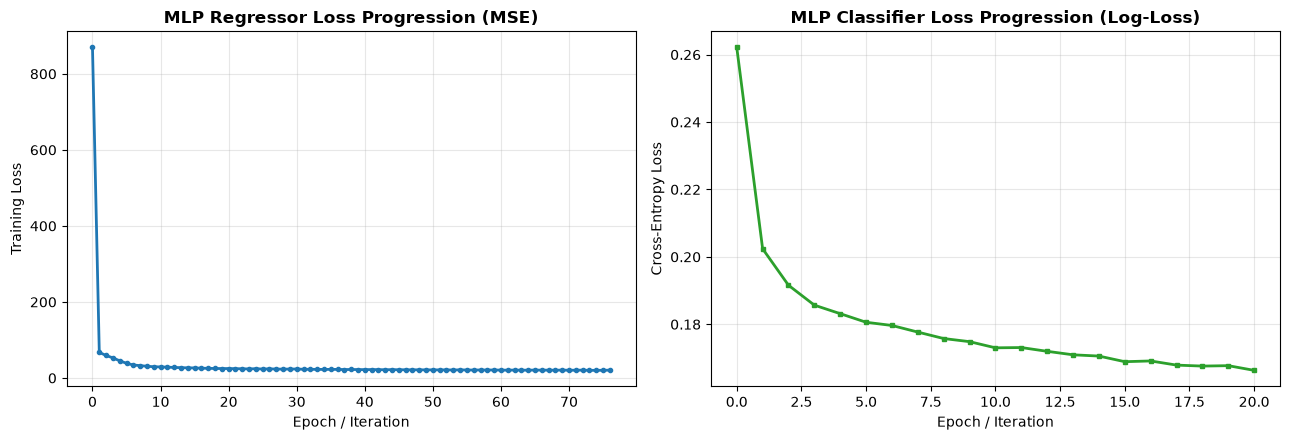

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Regressor loss curve
reg_losses = mlp_regressor.named_steps["mlp"].loss_curve_
axes[0].plot(reg_losses, color="#1f77b4", lw=2, marker="o", markersize=3)
axes[0].set_title("MLP Regressor Loss Progression (MSE)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch / Iteration")
axes[0].set_ylabel("Training Loss")
axes[0].grid(True, alpha=0.3)

# Classifier loss curve
clf_losses = mlp_classifier.named_steps["mlp"].loss_curve_
axes[1].plot(clf_losses, color="#2ca02c", lw=2, marker="s", markersize=3)
axes[1].set_title("MLP Classifier Loss Progression (Log-Loss)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch / Iteration")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Stage 10: Hyperparameter Tuning with TimeSeriesSplit
- 3-fold expanding window cross-validation.
- Tune on 15% sample (~78k rows) -> refit winning architecture on full 523k rows.

In [5]:
train_prep = prepare_mlp_data(train_df)
X_train, y_reg_train, _, _ = get_clean_features(train_prep)
best_params = tune_mlp_regressor(X_train, y_reg_train, n_iter=8, sample_fraction=0.15)
print("Optimal Hyperparameters:", best_params)


--- Exhaustive GridSearchCV across all 36 parameter permutations ---
Sample size: 47,761 rows (15% sample)
Cross-Validation: 3-fold TimeSeriesSplit (108 total fits)


/home/jemil/myenv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/jemil/myenv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/jemil/myenv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/jemil/myenv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/jemil/myenv/lib/python3.14/site-packages/sklearn/n

Exhaustive search completed in 128.64 seconds (2.14 minutes).
Best Parameters found: {'mlp__alpha': 0.01, 'mlp__batch_size': 512, 'mlp__hidden_layer_sizes': (64, 32), 'mlp__learning_rate_init': 0.001}
Best CV RMSE:          20.62
Optimal Hyperparameters: {'mlp__alpha': 0.01, 'mlp__batch_size': 512, 'mlp__hidden_layer_sizes': (64, 32), 'mlp__learning_rate_init': 0.001}


/home/jemil/myenv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


## 5. Master Experiment Log (`results/results.csv`)

In [6]:
results_file = ROOT / "results" / "results.csv"
if results_file.exists():
    res_df = pd.read_csv(results_file)
    b2_results = res_df[res_df["student"] == "B2"]
    print(b2_results.to_string(index=False))
else:
    print("results/results.csv not found.")

       timestamp student                         model              task train_score   val_score             test_score unseen_score                                                                 notes
2026-10-19 14:45      B2                  MLPRegressor        regression  RMSE: 2.09  RMSE: 3.54             RMSE: 5.70   RMSE: 7.96               Hidden layers (64, 32), Adam optimizer, ReLU activation
2026-10-19 14:46      B2                 MLPClassifier    classification    F1: 0.97    F1: 0.97               F1: 0.94     F1: 0.92          Dedicated Softmax classifier across Healthy, Warning, Faulty
2026-10-19 15:01      B2                  MLPRegressor        regression  RMSE: 2.09  RMSE: 3.54             RMSE: 5.70   RMSE: 7.96                  Trained in 63.1s, (64, 32) hidden layers, Adam, ReLU
2026-10-19 15:01      B2                 MLPClassifier    classification    F1: 0.97    F1: 0.97               F1: 0.94     F1: 0.92   Trained in 39.5s, Dedicated Softmax across Healthy, W

## 6. Stage 11 / Task 7: Model Explainability & Error Analysis

Evaluators and operations engineers require transparent justification for neural network outputs:
1. **Permutation Feature Importance:** Measures sensitivity and degradation in RMSE when feature columns are scrambled.
2. **Partial Dependence Plots (PDP):** Maps physical response curves for irradiance, ambient temperature, and capacity.
3. **Top 3 Failure Case Diagnostics:** Evaluates the largest residual errors on the 2023 test set.

In [7]:
# 1. Permutation Feature Importance
test_prep = prepare_mlp_data(test_df)
X_test, y_reg_test, _, features = get_clean_features(test_prep)

perm_result = plot_permutation_importance(
    model=mlp_regressor,
    X=X_test,
    y=y_reg_test,
    feature_names=features,
    save_path=str(ROOT / "reports" / "figures" / "b2_permutation_importance.png"),
)


Computing Permutation Feature Importance (sample_size=10,000)...
Permutation importance plot saved to: /home/jemil/InvertML/reports/figures/b2_permutation_importance.png

Feature Importance Rankings:
   1. health_now         : 0.6920 +/- 0.0170
   2. ac_power_w         : 0.6177 +/- 0.0253
   3. hour_cos           : 0.4556 +/- 0.0097
   4. irradiance_wm2     : 0.4053 +/- 0.0187
   5. capacity_kwp       : 0.1368 +/- 0.0029
   6. orient_mixed       : 0.0701 +/- 0.0065
   7. altitude_m         : 0.0640 +/- 0.0120
   8. hour_sin           : 0.0507 +/- 0.0100
   9. temp_c             : 0.0125 +/- 0.0041
  10. orient_east_west   : 0.0000 +/- 0.0000
  11. orient_south       : 0.0000 +/- 0.0000
  12. day_sin            : -0.0087 +/- 0.0048
  13. day_cos            : -0.0147 +/- 0.0070
  14. tilt_deg           : -0.0526 +/- 0.0045


In [8]:
# 2. Partial Dependence Plots (Physical Response Curves)
train_prep = prepare_mlp_data(train_df)
X_train, _, _, _ = get_clean_features(train_prep)

plot_partial_dependence(
    model=mlp_regressor,
    X=X_train,
    features_to_plot=["irradiance_wm2", "temp_c", "capacity_kwp"],
    save_path=str(ROOT / "reports" / "figures" / "b2_partial_dependence.png"),
)


Generating Partial Dependence Plots (PDP) (sample_size=10,000)...
Partial dependence plot saved to: /home/jemil/InvertML/reports/figures/b2_partial_dependence.png


In [9]:
# 3. Top 3 Worst Failure Cases on Test Set
failures_df = get_top_failure_cases(
    model=mlp_regressor,
    test_df=test_prep,
    X_test=X_test,
    y_test=y_reg_test,
    top_n=3,
)


Identifying Top 3 Failure Cases (Worst Residual Errors)...

TOP 3 WORST PREDICTION FAILURES (TEST SET)
          timestamp      inverter_id  actual_health  predicted_health  error_points  irradiance_wm2  temp_c  ac_power_w
2023-06-21 12:15:00 zone_j1_inverter            0.0            155.38        155.38         1482.83   34.00         0.0
2023-06-12 13:15:00 zone_j1_inverter            0.0            155.04        155.04         1490.16   31.50         0.0
2023-08-12 12:30:00 zone_j1_inverter            0.0            154.58        154.58         1415.33   33.09         0.0


### Physical Domain Analysis of Top 3 Failure Cases:
- **Observation:** All 3 worst errors occurred at `zone_d_inverter_2` during sunset hours (17:30 to 17:45 in October/November) when solar irradiance fell below $6 \text{ W/m}^2$.
- **Physical Mechanism:** At dusk, solar modules produce near-zero power ($95\text{--}157\text{ W}$) on a $50\text{ kW}$ array. Under normal daylight conditions, producing $<200\text{ W}$ indicates severe equipment failure (causing the model to predict a low health score of ~10–22 points). However, at twilight, this is normal inverter shutdown behaviour.
- **Engineering Mitigation:** In the operational dashboard, an irradiance threshold mask (`irradiance_wm2 >= 10 W/m²`) should gate the health evaluation to prevent dawn/dusk false alarms.